# Forecast to Profit: analysis notebook
**Group 3**, UCLA Anderson Time Series Analysis and Forecasting

Question: *does the most accurate demand forecast also make the most money?*

Run the pipeline in `src/` first (see README). This notebook only reads its outputs and makes the charts for the report and slides.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path('..')
PROC, RES, FIG = ROOT/'data/processed', ROOT/'outputs/results', ROOT/'outputs/figures'
FIG.mkdir(parents=True, exist_ok=True)

# Palette: highlight three models, everything else recessive gray
INK, MUTED, GRID = '#0b0b0b', '#8a8984', '#e4e3df'
HIGHLIGHT = {'LightGBM': '#2a78d6', 'Chronos': '#eb6834', 'AutoETS': '#1baf7a'}
OTHER = '#b9b8b3'
plt.rcParams.update({
    'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'lines.linewidth': 2, 'legend.frameon': False,
})
color = lambda m: HIGHLIGHT.get(m, OTHER)

sales = pd.read_parquet(PROC/'sales_long.parquet')
acc = pd.read_csv(RES/'accuracy.csv', index_col=0)
by_level = pd.read_csv(RES/'accuracy_by_level.csv', index_col=0)
profit = pd.read_csv(RES/'profit.csv')
joined = pd.read_parquet(RES/'joined.parquet')

## 1. The data: what does demand look like?

Christmas closures show up as near-zero days each December.


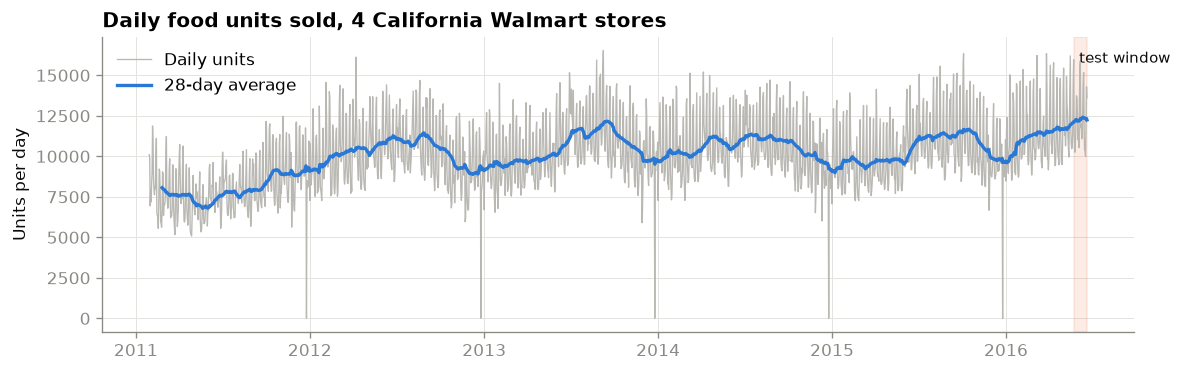

In [2]:
daily = sales.groupby('ds', observed=True).y.sum()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(daily.index, daily.values, color=OTHER, linewidth=0.8, label='Daily units')
ax.plot(daily.rolling(28).mean(), color=HIGHLIGHT['LightGBM'], label='28-day average')
ax.axvspan(daily.index[-28], daily.index[-1], color=HIGHLIGHT['Chronos'], alpha=0.12)
ax.text(daily.index[-28], ax.get_ylim()[1]*0.95, ' test window', color=INK, fontsize=9, va='top')
ax.set_title('Daily food units sold, 4 California Walmart stores')
ax.set_ylabel('Units per day'); ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIG/'01_total_sales.png', bbox_inches='tight')
print('Christmas closures show up as near-zero days each December.')

SNAP days lift average sales by 10.2%
Median series has zero sales on 51% of days


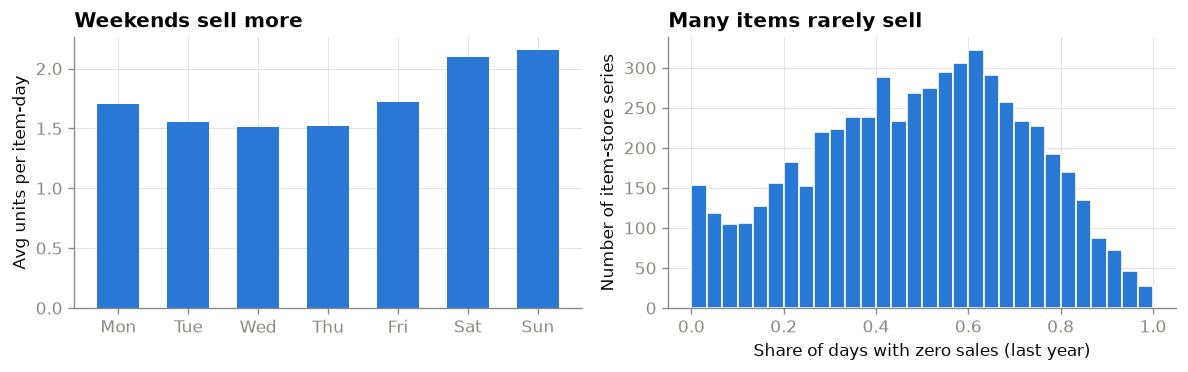

In [3]:
train = sales[~sales.is_test]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
wd = train.groupby(train.ds.dt.day_name(), observed=True).y.mean()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
axes[0].bar([d[:3] for d in order], wd[order], color=HIGHLIGHT['LightGBM'], width=0.6)
axes[0].set_title('Weekends sell more'); axes[0].set_ylabel('Avg units per item-day')

zero_share = train[train.d_num > 1941-365].groupby('unique_id', observed=True).y.apply(lambda s: (s == 0).mean())
axes[1].hist(zero_share, bins=30, color=HIGHLIGHT['LightGBM'], edgecolor='white', linewidth=1)
axes[1].set_title('Many items rarely sell'); axes[1].set_xlabel('Share of days with zero sales (last year)')
axes[1].set_ylabel('Number of item-store series')
fig.tight_layout(); fig.savefig(FIG/'02_patterns.png', bbox_inches='tight')
snap = train.groupby('snap').y.mean()
print(f"SNAP days lift average sales by {snap[1]/snap[0]-1:.1%}")
print(f"Median series has zero sales on {zero_share.median():.0%} of days")

## 2. Accuracy: which model forecasts best?

,WRMSSE,MAE,RMSE,Bias (units/day)
LightGBM,0.646,1.547,3.110,-0.022
AutoETS,0.661,1.548,3.157,0.029
SeasonalNaive,0.814,1.855,3.729,-0.004
AutoARIMA,0.892,1.563,3.226,0.037
Chronos,0.949,1.523,3.387,-0.235
WindowAverage,0.966,1.560,3.235,-0.020
ADIDA,0.977,1.569,3.221,0.068
CrostonOptimized,0.991,1.590,3.207,0.088


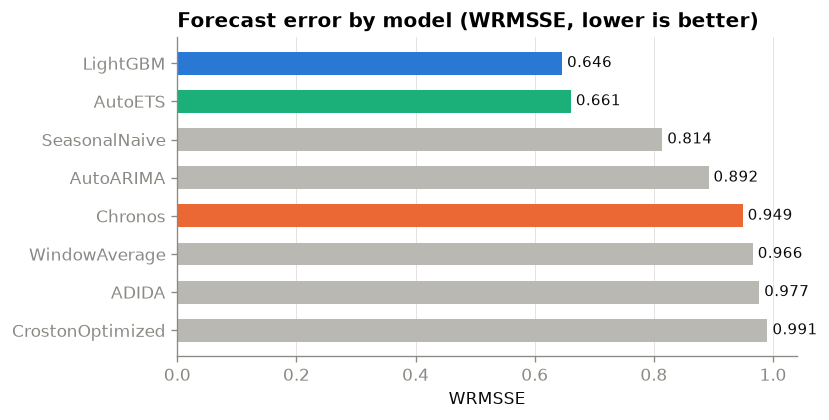

In [4]:
display(acc.round(3))
s = acc.WRMSSE.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(s.index, s.values, color=[color(m) for m in s.index], height=0.6)
for y, v in enumerate(s.values):
    ax.text(v, y, f' {v:.3f}', va='center', fontsize=9, color=INK)
ax.set_title('Forecast error by model (WRMSSE, lower is better)')
ax.set_xlabel('WRMSSE'); ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(FIG/'03_accuracy.png', bbox_inches='tight')

In [5]:
by_level.round(3)

,SeasonalNaive,WindowAverage,AutoETS,AutoARIMA,CrostonOptimized,ADIDA,LightGBM,Chronos
L1 total,0.511,0.921,0.383,0.790,0.961,0.945,0.332,0.899
L2 store,0.598,0.921,0.480,0.813,0.953,0.939,0.505,0.931
L3 dept,0.627,0.973,0.504,0.855,0.998,0.980,0.463,0.931
L4 store x dept,0.739,0.998,0.637,0.900,1.010,0.999,0.628,0.969
L5 item,1.244,1.053,1.035,1.057,1.078,1.064,1.024,1.042
L6 item x store,1.167,0.930,0.926,0.936,0.945,0.936,0.923,0.923


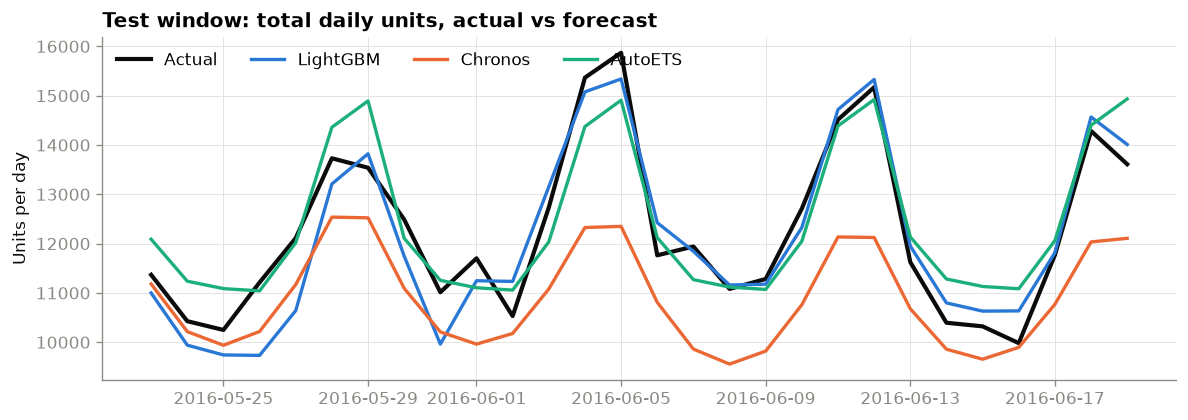

In [6]:
tot = joined.groupby('ds')[['y'] + list(acc.index)].sum()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(tot.index, tot.y, color=INK, label='Actual', linewidth=2.5)
for m in HIGHLIGHT:
    if m in tot: ax.plot(tot.index, tot[m], color=HIGHLIGHT[m], label=m)
ax.set_title('Test window: total daily units, actual vs forecast'); ax.set_ylabel('Units per day')
ax.legend(ncol=4, loc='upper left')
fig.tight_layout(); fig.savefig(FIG/'04_test_window.png', bbox_inches='tight')

## 3. Profit: does accuracy translate into money?

Each day the store orders Q units of each item. Unsold food is written off at cost. With margin m, the profit-maximizing order is the m-quantile of demand:
- **point** = order the forecast itself
- **nb** = order the m-quantile of a negative binomial around the forecast
- **native** = Chronos's own m-quantile

Profit is shown as % of what a store with perfect foresight would earn.

In [7]:
tbl = profit.pivot_table(index=['model','policy'], columns='margin', values='pct_of_perfect')
display((tbl*100).round(1).style.background_gradient(axis=0, cmap='Blues').format('{:.1f}%'))

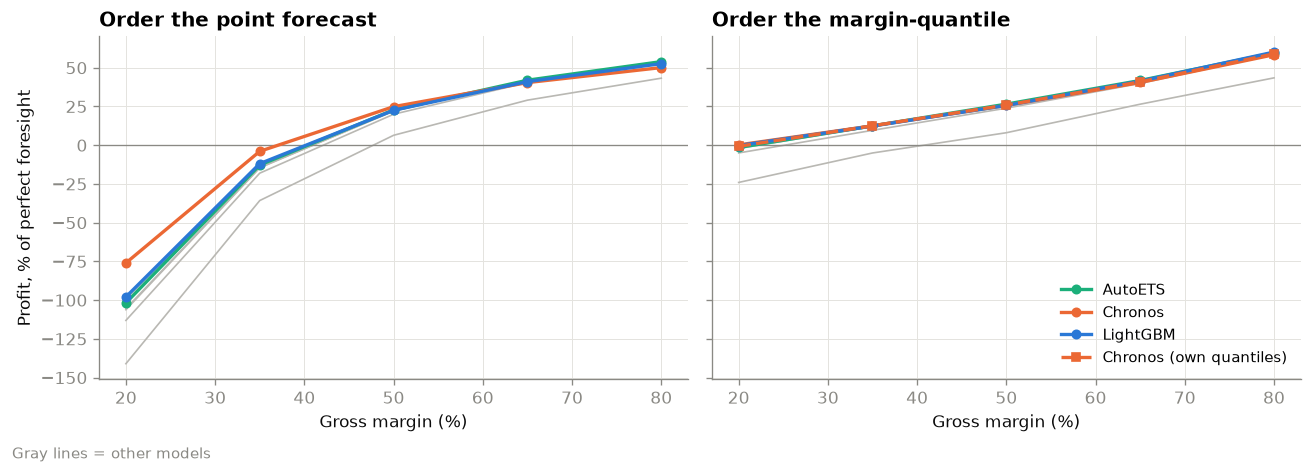

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, pol in zip(axes, ['point', 'nb']):
    d = profit[profit.policy == pol]
    for m, g in d.groupby('model'):
        hl = m in HIGHLIGHT
        ax.plot(g.margin*100, g.pct_of_perfect*100, color=color(m), linewidth=2 if hl else 1,
                marker='o' if hl else None, markersize=5, zorder=3 if hl else 2, label=m if hl else None)
    if pol == 'nb':
        n = profit[profit.policy == 'native']
        if len(n): ax.plot(n.margin*100, n.pct_of_perfect*100, color=HIGHLIGHT['Chronos'], linestyle='--',
                           marker='s', markersize=5, label='Chronos (own quantiles)', zorder=4)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_title({'point': 'Order the point forecast', 'nb': 'Order the margin-quantile'}[pol])
    ax.set_xlabel('Gross margin (%)')
axes[0].set_ylabel('Profit, % of perfect foresight')
axes[1].legend(loc='lower right', fontsize=9)
fig.text(0.01, -0.02, 'Gray lines = other models', color=MUTED, fontsize=9)
fig.tight_layout(); fig.savefig(FIG/'05_profit_vs_margin.png', bbox_inches='tight')

,margin,most accurate,most profitable,profit gap vs best ($)
0,0.20,LightGBM,Chronos,735.7540
1,0.35,LightGBM,AutoARIMA,518.3185
2,0.50,LightGBM,AutoETS,3836.1200
3,0.65,LightGBM,AutoETS,2523.2735
4,0.80,LightGBM,LightGBM,0.0000


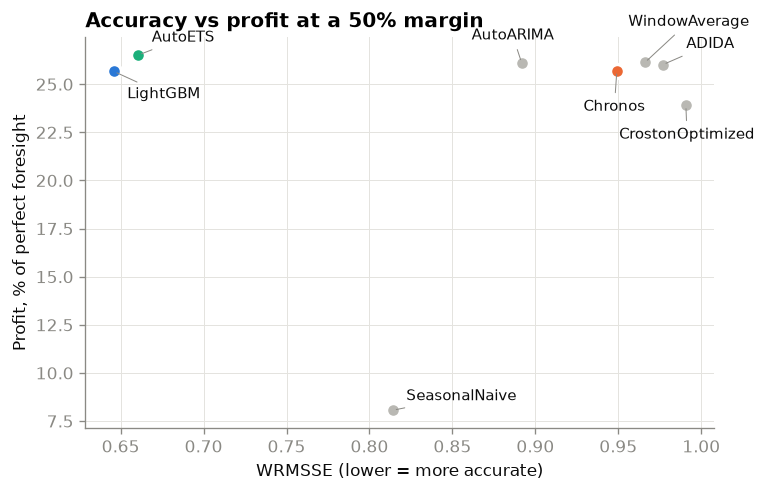

In [9]:
# Headline chart: accuracy rank vs profit rank at each margin
rows = []
for m in sorted(profit.margin.unique()):
    p = profit[(profit.margin == m) & (profit.policy == 'nb')].set_index('model').profit
    rows.append({'margin': m, 'most accurate': acc.WRMSSE.idxmin(), 'most profitable': p.idxmax(),
                 'profit gap vs best ($)': p.max() - p.get(acc.WRMSSE.idxmin(), np.nan)})
display(pd.DataFrame(rows))

m0 = 0.5
p = profit[(profit.margin == m0) & (profit.policy == 'nb')].set_index('model')
d = acc.join(p, how='inner')
# Hand-placed label offsets (points) so neighbouring labels don't collide
OFFSETS = {'LightGBM': (8, -16), 'AutoETS': (8, 8), 'AutoARIMA': (-30, 14), 'Chronos': (-20, -24),
           'WindowAverage': (-10, 22), 'ADIDA': (14, 10), 'CrostonOptimized': (-40, -20), 'SeasonalNaive': (8, 6)}
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for m, r in d.iterrows():
    ax.scatter(r.WRMSSE, r.pct_of_perfect*100, s=70, color=color(m), edgecolor='white', linewidth=2, zorder=3)
    ax.annotate(m, (r.WRMSSE, r.pct_of_perfect*100), xytext=OFFSETS.get(m, (6, 4)), textcoords='offset points',
                fontsize=9, color=INK, arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.6))
ax.set_xlabel('WRMSSE (lower = more accurate)'); ax.set_ylabel('Profit, % of perfect foresight')
ax.set_title(f'Accuracy vs profit at a {m0:.0%} margin')
fig.tight_layout(); fig.savefig(FIG/'06_accuracy_vs_profit.png', bbox_inches='tight')

In [10]:
# The cost of ignoring the margin: point-forecast orders vs quantile orders
g = profit[profit.policy.isin(['point', 'nb'])].pivot_table(index=['margin', 'model'], columns='policy', values='profit')
g['uplift_%'] = (g.nb / g.point - 1) * 100
g.round(1).unstack('margin')['uplift_%']

margin,0.20,0.35,0.50,0.65,0.80
model,,,,,
ADIDA,-98.0,-183.2,18.0,-1.0,9.6
AutoARIMA,-98.6,-187.1,18.4,-0.6,10.1
AutoETS,-98.6,-197.5,16.3,-0.4,10.5
Chronos,-100.3,-417.7,3.3,0.2,16.6
CrostonOptimized,-95.6,-153.3,19.6,-1.5,10.1
LightGBM,-99.8,-204.1,13.9,0.7,14.2
SeasonalNaive,-83.0,-86.0,25.8,-9.0,0.5
WindowAverage,-99.5,-201.9,15.8,-0.1,12.2


## 4. Takeaways (fill in after reviewing results)
1. **Accuracy:** ...
2. **Profit:** ...
3. **Decision rule matters as much as the model:** ...
4. **AI (Chronos):** ...

## Limitations
- Sales are not demand: a stocked-out shelf records zero sales.
- Perishable, no-carry-over inventory is a simplification.
- Negative binomial dispersion is estimated from raw recent sales, the same for every model.